<a href="https://colab.research.google.com/github/SRXKaiser/analitica-de-datos/blob/main/Practicas%20U3/Victor/Actividad_Serie_De_Tiempo%2023111511.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Datos Alumno**

# * **Nombre**: Victor Manuel Landeros Ramirez
# * **No control**: 23111511

#### **En esta actividad trabajarás con datos históricos del precio de mercado de la acción de alguna de las grandes compañías como Nvidia, Tesla, Google.**

Sigue los siguientes pasos para descargar los datos del problema:

    Ir a la página de Yahoo!-Finance: https://finance.yahoo.com/

En el buscador de dicha página pon las iniciales de la compañía deseada. Deberás seleccionar alguna de las siguientes compañías: AAPL, NVDA, TSLA, GOOG, AMZN o MSFT.

Seleccionar la pestaña "Historical Data".

Pulsa "Download" para descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.



# **En esta Actividad se trabajará con los datos historicos del precio de mercado de la acción, Compañia NVDA.**

# **0 - Preparando los datos ORIGINALES**

In [ ]:
# Omitamos los Warnings por el momento:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
!pip freeze   # Si deseas verificar qué librerías y versiones ya tiene google-Colab preinstaladas,
               # en particular "prophet" que usaremos en este ejercicio.

absl-py==2.0.0
accelerate==1.15.0
access==1.1.10.post3
affine==3.0.1
aiofiles==25.1.0
aiohappyeyeballs==2.7.1
aiohttp==3.14.5
aiosignal==1.4.0
aiosqlite==0.22.1
alabaster==1.0.0
albucore==0.0.24
albumentations==2.0.8
ale-py==0.12.1
altair==5.5.0
annotated-doc==0.0.5
annotated-types==0.8.0
anyio==4.16.0
anywidget==0.9.21
apsw==3.54.1.0
argon2-cffi==25.1.0
argon2-cffi-bindings==26.1.0
array_record==0.8.6
arrow==1.4.0
arviz==0.22.0
astropy==7.2.3
astropy-iers-data==0.2026.11.2.0.34.55
astunparse==1.6.3
atpublic==5.1
attrs==26.1.0
audioop-lts==0.2.2
audioread==3.1.0
Authlib==1.9.3
autograd==1.9.1
babel==2.18.0
backcall==0.2.0
beartype==0.23.1
beautifulsoup4==4.13.5
betterproto==2.0.0b7
bigframes==2.51.0
bigquery-magics==0.14.0
bleach==6.4.0
blinker==1.9.0
blis==1.3.4
blobfile==3.3.0
blosc2==4.14.1
bokeh==3.8.2
Bottleneck==1.4.2
bqplot==0.12.47
branca==0.8.2
brotli==1.2.1
CacheControl==0.14.4
cachetools==6.2.6
catalogue==2.0.10
certifi==2026.10.23
cffi==2.1.1
chardet==5.2.0
charset-normaliz

In [ ]:
!pip install yfinance

In [ ]:

#Libreria para obtener el conjunto de datos
import yfinance as yf

#Para manipular datos
import numpy as np
import pandas as pd

#Para graficar
import matplotlib.pyplot as plt

#Error cuadratico medio
from sklearn.metrics import mean_squared_error
import math

#Para aplicar escalamiento de datos [0,1]
from sklearn.preprocessing import MinMaxScaler

from prophet import Prophet
from statsmodels.graphics.tsaplots import month_plot, quarter_plot
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf   # gráficos de autocorrelación

#A) **Descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.**

In [ ]:
#Escribimos las iniciales de la compañia con la que deseemos trabajar. En esta ocasión trabajare con Tesla

ticker_symbol = 'NVDA'                           # selecciona las iniciales de la compañía deseada.
#data = yf.download(ticker_symbol, period='5y')   # Se indica el período de 5 años y descargamos.

#segunda forma, ya que no se esta incluyendo la columna de date en el df descargado
#definirn el rango de fechas a descargar (5 años)
start_date = "2021-11-17"
end_date = "2026-11-17"

#convierte a dataframe
#auto_adjust=False para incluir adj close
df = yf.download(ticker_symbol, start=start_date, end=end_date, auto_adjust=False)   #header=2 para que no tome en cuenta los 2 primeros renglones, ya que estan vacios
#df.columns=['Date','Adj Close','Close','High','Low','Open','Volume'] #Se agrega columna Date


#esta cosa si es importante, sirve para quitar el multiindex, osea solo quede una fila de encabezados
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)
df.columns.name = None
df =df.reset_index()

df.head()


[*********************100%***********************]  1 of 1 completed


,Date,Adj Close,Close,High,Low,Open,Volume
0,2021-11-17,29.132683,29.261000,30.509001,28.799999,30.417999,428508000
1,2021-11-18,31.536097,31.674999,32.759998,31.320999,32.367001,781711000
2,2021-11-19,32.840351,32.985001,33.088001,31.905001,32.243000,533867000
3,2021-11-22,31.815866,31.955999,34.646999,31.900000,33.516998,754335000
4,2021-11-23,31.606783,31.746000,32.360001,30.879999,31.535000,532163000


In [ ]:
df.info()   # Verifica detalles del conjunto de datos a utilizar
            # El dataframe cuenta con 1258 registros
            # 7 columnas las cuales son: Date, Adj close, Close, High, Low, Open, Volume
            # Variable Date, tipo Object -> se cambiará a tipo Fecha

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       1254 non-null   datetime64[ns]
 1   Adj Close  1254 non-null   float64       
 2   Close      1254 non-null   float64       
 3   High       1254 non-null   float64       
 4   Low        1254 non-null   float64       
 5   Open       1254 non-null   float64       
 6   Volume     1254 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 68.7 KB


#**B)Utiliza solamente los datos de la columna "Adj Close" en esta actividad.**

In [ ]:
# Renombremos de manera estándar las columnas de fechas y valores de la
# serie de tiempo, donde además la fecha la trasnformamos a tipo datetime:

df = df.drop(columns=['Close','High','Low','Open','Volume']) #Elimina columnas que no se requieren
df = df.rename(columns={'Adj Close':'y'})                    #Columna Adj Close, renombramos por y
df['Date'] = pd.to_datetime(df['Date'])                      #Convertimos variable Date de tipo Object a Datetime
df.head()                                                    #Muestra primeros 5 registros para visualizar el cambio

,Date,y
0,2021-11-17,29.132683
1,2021-11-18,31.536097
2,2021-11-19,32.840351
3,2021-11-22,31.815866
4,2021-11-23,31.606783


In [ ]:
df.info() #Creación de un nuevo df, el cual consta de 2 columnas, las cuales son:
          #Variable Date -> de tipo datetime64, nos ayuda a representar un rango de fechas muy amplio con presición nanosegundos
          #Variable 'Adj Close' -> fue renombrada por 'y' de tipo flotante,

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    1254 non-null   datetime64[ns]
 1   y       1254 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 19.7 KB


En particular datetime64[ns] nos ayuda a representar un rango de fechas muy amplio con precisión de nanosegundos.

### **Agreguemos los ajustes usuales en Series de tiempo:**

In [ ]:
# Hagamos una copia del DataFrame df con índices temporales:

df_temp = df.copy()                     #Genera copia del df originar en nueva variable temporal de nombre: df_temp
df_temp.set_index('Date', inplace=True) #se establece como indice Variable Date,
                                        #parametro inplace=True, es para guardar los cambios
df_temp.head()                          #visualizar los cambios

,y
Date,
2021-11-17,29.132683
2021-11-18,31.536097
2021-11-19,32.840351
2021-11-22,31.815866
2021-11-23,31.606783


In [ ]:
#Muestra información sobre numero total de registros y columnas como estan conformados el df original (df) y el df temporal (df_temp)

print("DataFrame Original:\n ")
print(df.shape)      #Conformado por 1258 registros y 2 columnas (Date, y)

print("\nDataFrame Temporal:\n")
print(df_temp.shape) #Conformado por 1258 regsitros y 1 columna (y), Variable Date pase a ser indice

DataFrame Original:
 
(1254, 2)

DataFrame Temporal:

(1254, 1)


https://pandas.pydata.org/docs/reference/api/pandas.DatetimeIndex.html

In [ ]:
# Ajustemos la frecuencia de los índices, para que el modelo tenga información del período en que
# se encuentran los datos:

df_temp.index =df_temp.index.tz_localize(None) #Para quitar zona horaria
df_temp.index


DatetimeIndex(['2021-11-17', '2021-11-18', '2021-11-19', '2021-11-22',
               '2021-11-23', '2021-11-24', '2021-11-26', '2021-11-29',
               '2021-11-30', '2021-12-01',
               ...
               '2026-11-03', '2026-11-04', '2026-11-05', '2026-11-06',
               '2026-11-09', '2026-11-10', '2026-11-11', '2026-11-12',
               '2026-11-13', '2026-11-16'],
              dtype='datetime64[ns]', name='Date', length=1254, freq=None)

-----------------------------------------------------------------------------
**Se puede observar que la ejecución se esta línea de código indica 'freq=None', por lo cual tendremos que definir un tipo de frecuencia (ya sea por dias, meses, años). La cual se definirá en el siguiente segmento de código que se muestra a continuación:**

-----------------------------------------------------------------------------

Para las opciones de "freq" ver la tabla que viene en esta liga:

https://pandas.pydata.org/pandas-docs/stable/user_guide/timeseries.html#offset-aliases

In [ ]:
# Especifiquemos entonces que nuestros datos están registrados con una frecuencia mensual
# al inicio del mes (cada día 01 de cada mes):

#se quedara la frecuencia B de dias habiles
df_temp = df_temp.resample('B').asfreq()#Define frecuencia B -> frecuencia del día de actividad
df_temp.index

DatetimeIndex(['2021-11-17', '2021-11-18', '2021-11-19', '2021-11-22',
               '2021-11-23', '2021-11-24', '2021-11-25', '2021-11-26',
               '2021-11-29', '2021-11-30',
               ...
               '2026-11-03', '2026-11-04', '2026-11-05', '2026-11-06',
               '2026-11-09', '2026-11-10', '2026-11-11', '2026-11-12',
               '2026-11-13', '2026-11-16'],
              dtype='datetime64[ns]', name='Date', length=1304, freq='B')

#**C)Investiga el significado de esta columna Adj-Close e inclúyelo en tu reporte del Jupyter-Notebook.**

###Investigación

-------------------------------------------------------------------------
¿Qué es el Cierre Ajustado?

Adj Close es una columna Clave dentro de los datos historicos . El **Precio Ajustado de cierre**, se apoya de dividendos y splist de acciones, que afectan el precio de la acción.

Es una versión ajustada del Precio de Cierre de una acción, después de los ajustes para todas las distribuciones de splits y dividendos aplicables, los cuales se definen a continuación:

 * **Dividendos**, Aqui es cuando la empresa distribuye dividendos a sus accionistas. El dividendo se "resta" del precio de la acción para representar el valor real de la acción después del pago realizado.

* **Splits(Divisiones de Acciones)**, Aqui es cuando el precio de la acción se ajusta para reflejar la nueva cantiad de acciones en circulación. Aumenta el número de acciones de circulación, pero la capitalización no cambia

##Importancia del Adj Close

El Adj Close, es muy importante ya que gracias a el se puede visualizar de mejor la manera la evolución del valor de la acción que se ha tenido a lo largo del tiempo. Siendo muy útil al momenteo de realizar análisis de rendimiento y asi lograr obtener una visipon más clara de cómo se ha comportado una acción dentro del mercado por un periodo de tiempo

De igual manera también es muy útil para realizar cálculos más precisos, si se desea cálcular el rendimiento total de una acción o retornos de una inversión en un cierto periodo, ya que por otro lado si se hace uso unicamente de "close" sin el ajuste, puede existir sesgo en el análisis.

--------------------------------------------------------------------

#**D)Divide los datos en Train y Test, donde Test serán los últimos 20 precios de mercado de la compañía que seleccionaste**

In [ ]:
df_temp=df_temp.ffill() #para rellenar datos faltantes NaN
datos_nan=df_temp[df_temp.isna().any(axis=1)] #para verificar existencia datos faltantes
#print(datos_nan)

In [ ]:
# Particionemos en entrenamiento y prueba como DataFrames de Pandas:
train = df_temp.iloc[0:-20,:] # Selecciona todos los registros, excepto últimos 20
test = df_temp.iloc[-20:,:]   # Seleccionamos los datos del últimoS 20 registros para predicción de Test.

In [ ]:
test.head()  #muestra registros del test

,y
Date,
2026-10-20,216.470001
2026-10-21,221.970001
2026-10-22,212.210007
2026-10-23,210.960007
2026-10-26,216.000000


In [ ]:
datos_nan=train[train.isna().any(axis=1)]
print(datos_nan) #verificamos que no existan datos faltantes NaN en Entrenamiento (train)

datos_nan=test[test.isna().any(axis=1)]
print(datos_nan) #verificamos que no exista datos faltantes NaN en Pueba (test)

Empty DataFrame
Columns: [y]
Index: []
Empty DataFrame
Columns: [y]
Index: []


In [ ]:
train.shape #Entrenamiento conformado por 1284 registros y 1 columna

(1284, 1)

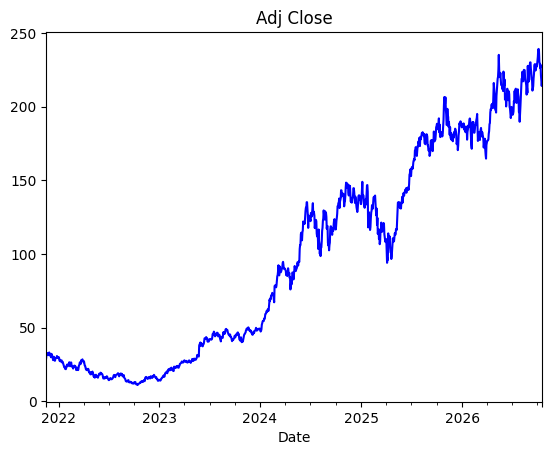

In [ ]:
# Gráfico con la periodicidad anual:
train['y'].plot(title='Adj Close', style='-b')
plt.show()

## <font color=orange>**Escriba su Interpretación de la gráfica**</font>





## <font color=orange>**De este gráfico podemos observar:**

1. La gráfica muestra cómo cambió el precio de cierre ajustado de NVIDIA en el conjunto de entrenamiento.
2. Durante 2022, el precio bajó de alrededor de 30 dólares a poco más de 10 dólares.
3. En 2023 comenzó la recuperación y, a partir de 2024, el crecimiento se hizo más marcado.
4. En 2025 hubo una caída cercana a los 100 dólares, seguida de una recuperación. También se observan movimientos más amplios en los últimos años.
5. Al final del período de entrenamiento, el precio superó los 200 dólares. La tendencia general fue ascendente, con varias caídas en el camino.


# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ORIGINALES**

*   El modelo ingenuo simplemente **hace la predicción del siguiente período, repitiendo el valor del último período**.

*   Este modelo se utiliza en general como punto de partida **para comparar todos los demás**.

*   Utilicemos el error RMSE (Raíz del Error Cuadrático Medio) como medida del desempeño de nuestros modelos a obtener.

In [ ]:
test['y'].values #muestra valores del conjunto test en arreglo

array([216.47000122, 221.97000122, 212.21000671, 210.96000671,
       216.        , 217.94000244, 215.38000488, 213.66000366,
       204.63999939, 202.05999756, 206.69000244, 200.13000488,
       181.6000061 , 186.63999939, 178.66999817, 168.88999939,
       173.72999573, 166.19000244, 162.8500061 , 156.13999939])

In [ ]:
history = [x for x in train['y'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test['y'])):
  # Obtenemos las predicciones:
  yhat = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat)

  # Observaciones-registros reales:
  obs = test.iloc[i]['y']   # Ahora vamos tomando los datos de Test.
  history.append(obs)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-Naive: RMSE: %.3f' % rmse)

>Esperado-real = 216, Predicción = 217.090
>Esperado-real = 221, Predicción = 216.470
>Esperado-real = 212, Predicción = 221.970
>Esperado-real = 210, Predicción = 212.210
>Esperado-real = 216, Predicción = 210.960
>Esperado-real = 217, Predicción = 216.000
>Esperado-real = 215, Predicción = 217.940
>Esperado-real = 213, Predicción = 215.380
>Esperado-real = 204, Predicción = 213.660
>Esperado-real = 202, Predicción = 204.640
>Esperado-real = 206, Predicción = 202.060
>Esperado-real = 200, Predicción = 206.690
>Esperado-real = 181, Predicción = 200.130
>Esperado-real = 186, Predicción = 181.600
>Esperado-real = 178, Predicción = 186.640
>Esperado-real = 168, Predicción = 178.670
>Esperado-real = 173, Predicción = 168.890
>Esperado-real = 166, Predicción = 173.730
>Esperado-real = 162, Predicción = 166.190
>Esperado-real = 156, Predicción = 162.850

Error-Modelo-Naive: RMSE: 7.011


----------------------------------------------------------------------------
## <font color=orange>**Interpretación**
El modelo ingenuo utiliza el último precio observado para estimar el siguiente. En varios registros, la predicción quedó cerca del valor real, pero la diferencia aumentó cuando el precio cambió de golpe. Por ejemplo, cuando el valor real cayó a cerca de 182 dólares, el modelo todavía pronosticaba alrededor de 200.


-----------------------------------------------------------------------------

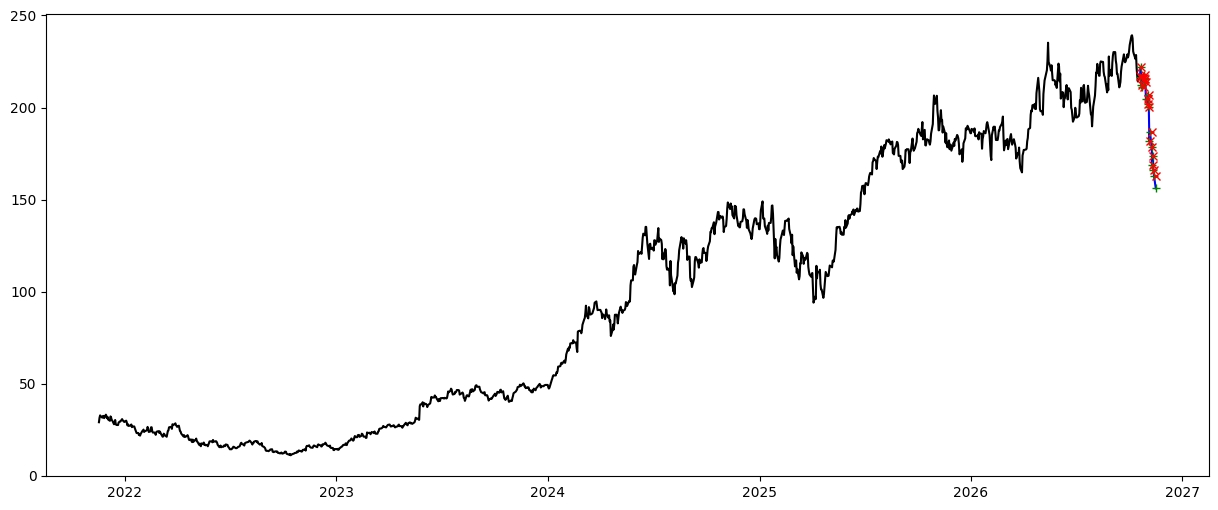

In [ ]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')   # Datos de entrenamiento (los históricos).
ax = plt.plot(test['y'], '-b')    # Datos de prueba reales (los últimos 20 registros a predecir).
ax = plt.plot(test['y'],'+g')
ax = plt.plot(test.index, predictions, 'xr')  # Predicciones del modelo ingenuo.

#Verdes son los datos reales
#rojos son las predicciones

### <font color=orange>**Interpretación Gráfica.**

----------------------------------------------------------------------------
La línea negra muestra el historial de entrenamiento, las marcas verdes señalan los precios reales de prueba y las cruces rojas representan las predicciones. Al final de la gráfica se aprecia que las cruces rojas siguen la caída del precio con un registro de retraso. Esto sucede porque el modelo refleja cada cambio después de observarlo.

----------------------------------------------------------------------------

# **2 - Modelo ARIMA**

# **DATOS ORIGINALES**

### **Análisis preliminar para obtener información de la serie de tiempo y construir el modelo ARIMA(p,d,q).**

*   **AR (AutoRegresivo):** El modelo se basa en la **relación entre un valor actual y sus valores pasados.**

*   **I (Integrado):** Se refiere a la diferenciación de la serie para hacerla estacionaria, es decir, eliminar tendencias y patrones cíclicos.

*   **MA (Media Móvil):** Usa el error de los valores pasados (las desviaciones entre valores predichos y observados) para corregir el valor actual.

##### **Ahora veamos el gráfico de descomposición de la serie de tiempo en sus componentes de tendencia (trend), estacionalidad (stationality) y residual (residual).**

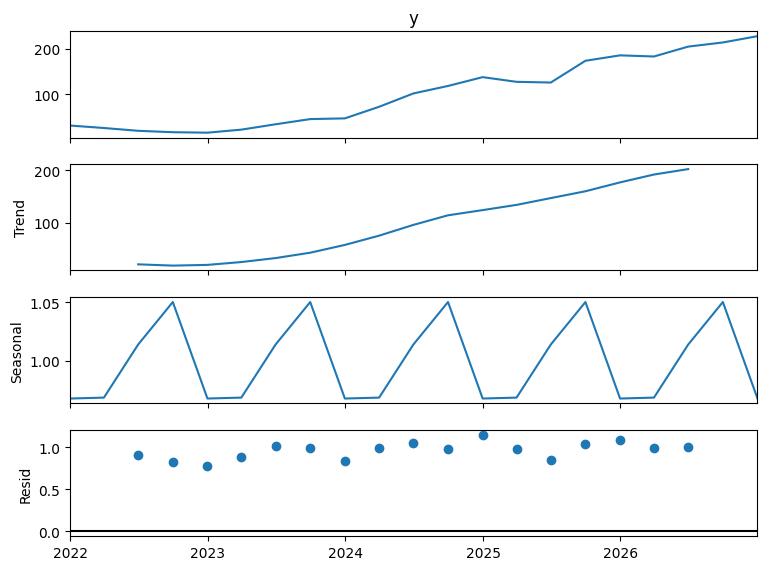

In [ ]:
# Gráficos de descomposición estacional:
#parametro Q indica año
decomposition = seasonal_decompose(train['y'].resample('Q').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

# <font color=orange>**Interpretación de cada una de las Gráficas**

-----------------------------------------------------------------------------

En esta gráfica nos desgloza 4 gráficas:

1. **Gráfica Original**, Los promedios trimestrales muestran una caída al inicio y un crecimiento más claro desde 2023, con algunas bajas temporales

2. **Tendencia (Trend)**, Al suavizar las variaciones de corto plazo, se aprecia mejor el crecimiento del precio a lo largo del período

3. **Estacional (Seasonal)**, La descomposición estima un patrón que se repite cada año. Los factores por encima de 1 elevan el nivel estimado y los que quedan por debajo de 1 lo reducen

4. **Residuos (Resid)**, Representan la parte que queda sin explicar después de considerar la tendencia y la estacionalidad. La mayoría se concentra cerca de 1, aunque algunos trimestres muestran desviaciones más visibles

-----------------------------------------------------------------------------

##### **Veamos ahora estos dos gráficos que nos hablan si tenemos algún tipo de estacionalidad (i.e., periodicidad). En particular, mensual o trimestral:**

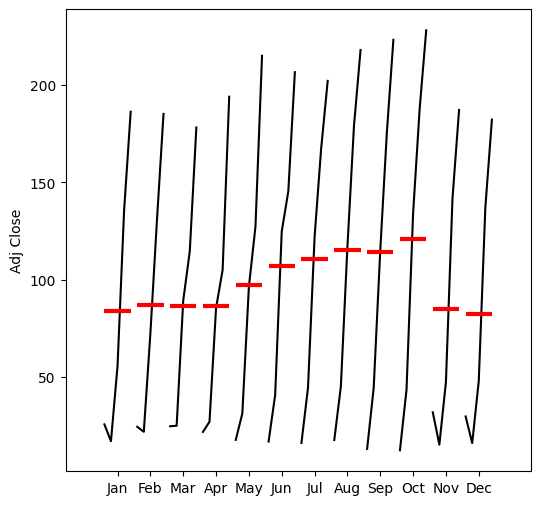

In [ ]:
# Gráfica para detección de estacionalidad mensual:
fig = month_plot(train['y'].resample('M').mean(), ylabel='Adj Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica**

-----------------------------------------------------------------------------
Las líneas rojas indican el precio promedio de cada mes en los años analizados. Octubre tuvo el promedio más alto. Las líneas negras muestran que el precio de un mismo mes cambió bastante entre años. Parte de esas diferencias puede explicarse por el crecimiento general de la acción durante el período


----------------------------------------------------------------------------

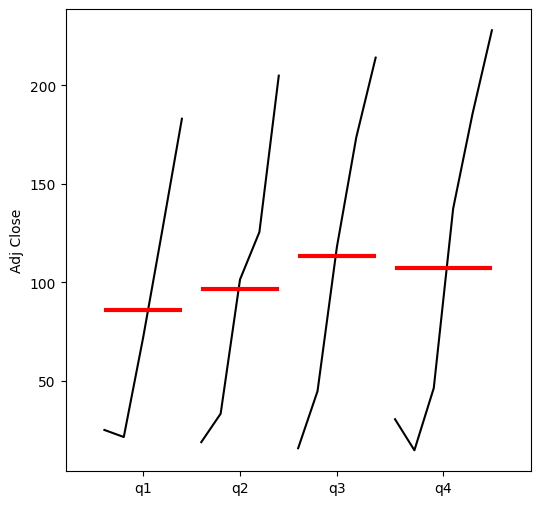

In [ ]:
# Si queremos graficar y detectar estacionalidad trimestral:
fig = quarter_plot(train['y'].resample('Q').mean(), ylabel='Adj Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica**

----------------------------------------------------------------------------
El tercer trimestre tuvo el promedio más alto, seguido por el cuarto, mientras que el primero registró el más bajo. Dentro de cada trimestre también se observa un aumento importante entre los primeros y los últimos años. Para saber si esta diferencia entre trimestres se repite de forma consistente, habría que revisar la serie después de quitar la tendencia

----------------------------------------------------------------------------

### **Gráficos de Autocorrelación (ACF) y Autocorrelación Parcial (PACF)**

*   Los gráficos de Autocorrelación miden la correlación entre la serie de tiempo y una versión rezagada de sí misma.

*   Este tipo de correlaciones de una serie de tiempo consigo misma son llamadas "autocorrelaciones" o "correlaciones seriales".

*   En el eje horizontal se muestra el valor del desfazamiento (lag) y en el eje vertical el valor de correlación de la serie desfazada y la original.

*   El cono sombreado indica intervalos de confianza de la correlación, con un 95% de confianza de manera predeterminada.

*   Que existan autocorrelaciones significativas en estos gráficos nos habla de que la serie de tiempo no es aleatoria.

*   En estos dos gráficos (llamados en inglés "pollipop plots") hay que determinar cuántos de estos lollipops están afuera del intervalo de confianza (sin contar el inicial) antes de que entre el siguiente a la zona celeste?

*   **Gráfico ACF:** Muestra la correlación total entre la serie y sus retardos, incluyendo efectos directos e indirectos.

*   **Gráfico PACF:** Muestra la correlación directa entre la serie y sus retardos, eliminando los efectos de los retardos intermedios.

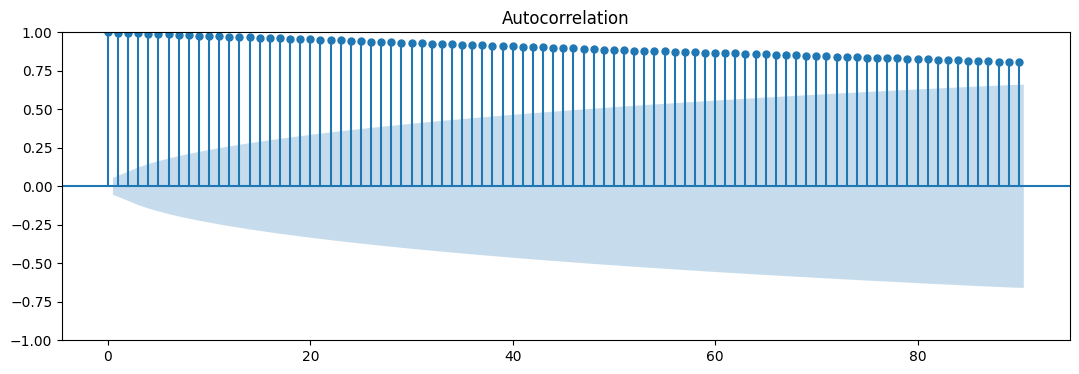

In [ ]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function)
train['y'] = train['y'].ffill() ##Rellenan campos que estan NaN
fig,ax = plt.subplots(figsize = (13,4))
plot_acf(train['y'], lags=90, ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
plt.show()

# <font color=orange>**Intepretación Gráfica Autocorrelación (ACF)**

-----------------------------------------------------------------------------
Sin contar el rezago 0, los 90 rezagos mostrados quedan por encima de la banda sombreada. La autocorrelación comienza cerca de 1 y disminuye lentamente hasta alrededor de 0.8. Esto indica que el nivel del precio mantiene una relación fuerte con sus valores anteriores. Como la serie tiene una tendencia marcada, conviene revisar la ACF después de diferenciarla antes de elegir el orden de media móvil de ARIMA


-----------------------------------------------------------------------------

El gráfico inicia con desfase (lag) de 0, lo cual es la correlación de la serie de tiempo consigo misma, la cual es 1.

Posteriormente se muestran las correlaciones de la serie de tiempo original, con la serie desfasada "q" lugares hacia atrás, es decir, de orden "q" en la componente MA de ARIMA(p,d,q).

**El gráfico ACF nos dice en primera instancia que la componente MA de ARIMA(p,d,q) tiene un grado "q" de 13 (en la práctica se puede buscar de 0 a 13).**

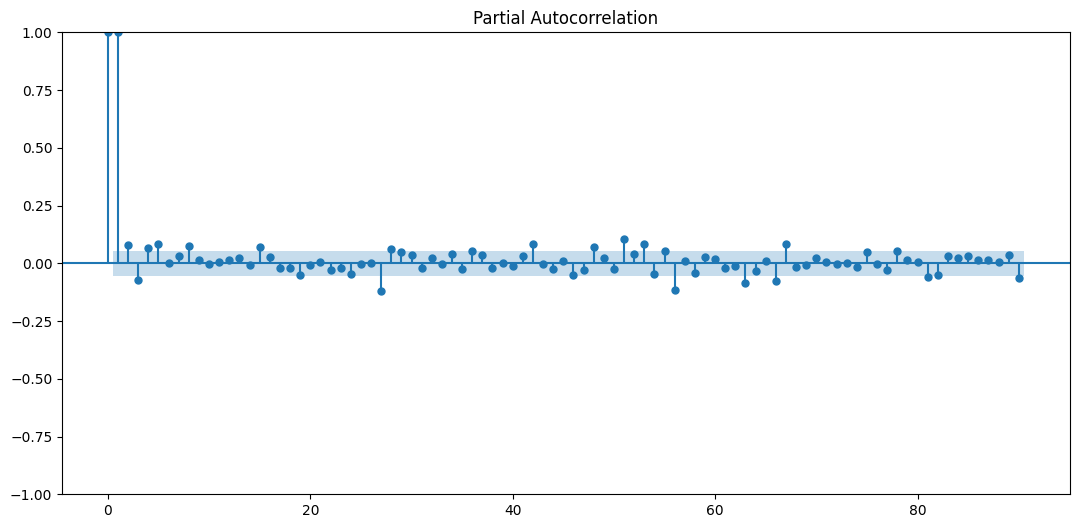

In [ ]:
# Gráfico de Autocorrelación Parcial (PACF):
fig, ax = plt.subplots(figsize = (13,6))
plot_pacf(train['y'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

# <font color=orange>**Interpretación Gráfica Partial Autoccorelation (PACF)**

----------------------------------------------------------------------------
Después del rezago 0, el rezago 1 sobresale claramente. Los demás valores son mucho menores y la mayoría se concentra cerca de cero, aunque algunos salen de la banda. Esto sugiere que el período anterior tiene la relación directa más fuerte con el precio actual. Para elegir el orden autorregresivo de ARIMA también conviene revisar la PACF de la serie diferenciada

----------------------------------------------------------------------------

* PACF también inicia con la correlación de la serie de tiempo consigo misma, por ello el valor de 1.

*   **De este gráfico podemos observar que la componente AR de ARIMA(p,d,q) tiene grado p=3 o tal vez 5 (en la práctica se puede probar de 0 a 5.)**

##### Existe un buen número de librerías para el caso de pronósticos con los modelos ARIMA-SARIMA. Usaremos en este ejercicio la de Statsmodels, cuya documentación encuentras en la siguiente liga:

https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

In [ ]:
# Lo primero es para quitar la estacionalidad y transformar un problema
# de tipo no-estacionario (SARIMA) en uno estacionario (ARIMA):

# Diferencia de datos consecutivos en el tiempo
# y podemos ahora usar ARIMA:
def difference(dataset, interval=1):
  diff = list()

  for i in range(interval, len(dataset)):
    value = dataset[i] - dataset[i - interval]
    diff.append(value)

  return np.array(diff)



# Invierte las diferencias anteriores, es decir, nos regresa la estacionalidad:
def inverse_difference(history, yhat, interval=1):
  return yhat + history[-interval]


In [ ]:
# Definamos la siguiente lista de registros de pasajeros en el tiempo:
history = [x for x in train.loc[:,'y'].values]   # train-ndarray : columna solo con los registros de pasajeros "y".
                               # history-list : lista con los datos del train.

predictions = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test['y'])):
  #
  months_in_year = 12
  diff = difference(history, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.    (p,d,q)  p->valor definido en gráfica partial autocorrelation  d->Estacionaria  q->valor definido en grafica autocorrelacion
  model = ARIMA(diff, order=(1,0,13),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit = model.fit(method_kwargs={'maxiter':300})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat = model_fit.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat = inverse_difference(history, yhat, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions.append(yhat)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs = test.iloc[i]['y']   #  cada dato es un flotante.
  history.append(obs)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 216, Predicción = 218.624


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


>Esperado-real = 221, Predicción = 217.117
>Esperado-real = 212, Predicción = 222.602
>Esperado-real = 210, Predicción = 213.260
>Esperado-real = 216, Predicción = 210.991
>Esperado-real = 217, Predicción = 215.397
>Esperado-real = 215, Predicción = 217.134
>Esperado-real = 213, Predicción = 216.269
>Esperado-real = 204, Predicción = 213.665
>Esperado-real = 202, Predicción = 205.160
>Esperado-real = 206, Predicción = 203.266
>Esperado-real = 200, Predicción = 207.188
>Esperado-real = 181, Predicción = 202.197
>Esperado-real = 186, Predicción = 183.609
>Esperado-real = 178, Predicción = 187.862
>Esperado-real = 168, Predicción = 179.780
>Esperado-real = 173, Predicción = 169.819
>Esperado-real = 166, Predicción = 173.603
>Esperado-real = 162, Predicción = 166.444
>Esperado-real = 156, Predicción = 164.052

Error-Modelo-ARIMA: RMSE: 7.476


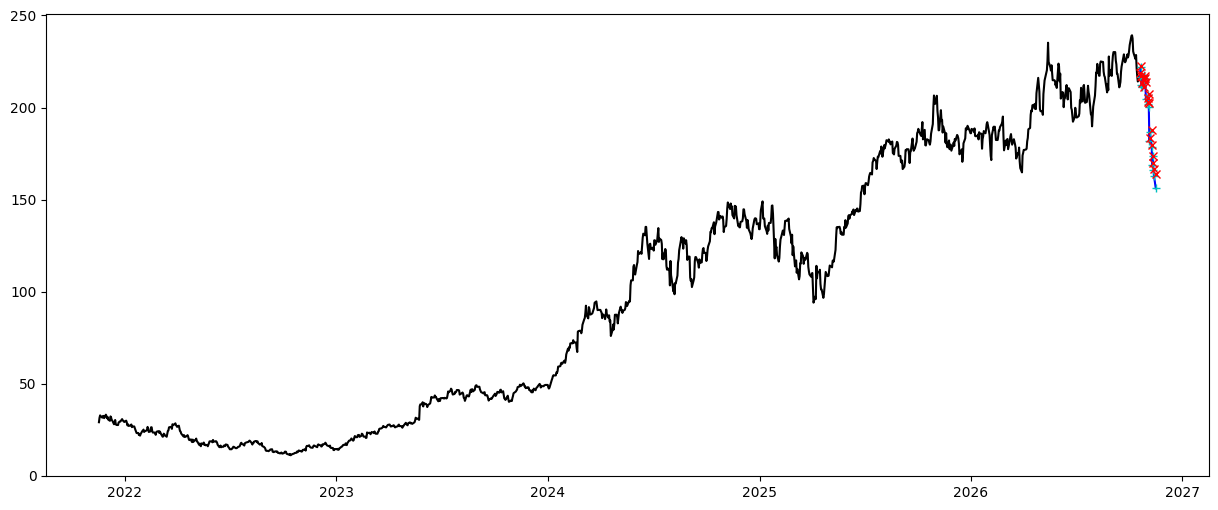

In [ ]:
# Veamos su gráfico de ARIMA:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')
ax = plt.plot(test['y'], '-b')
ax = plt.plot(test['y'], '+c')
ax = plt.plot(test.index, predictions, 'xr')

# <font color=orange>**Interpretación Gráfica ARIMA**

-----------------------------------------------------------------------------
Las cruces rojas son las predicciones de ARIMA y las marcas celestes muestran los precios reales de prueba. El modelo siguió la dirección de la caída, aunque en los descensos más fuertes varias predicciones quedaron por encima del precio observado. Su RMSE fue de 7.476 dólares, un poco mayor que los 7.011 dólares del modelo ingenuo


----------------------------------------------------------------------------



# **3 - Modelo Facebook-Meta-Prophet**

# **DATOS ORIGINALES**

#### **En la liga del modelo Facebook-Prophet puedes encontrar mucho más información, además de la documentación correspondiente:**

https://facebook.github.io/prophet/

In [ ]:
df_temp.head() #verificar que el df_temp este en formato correcto

,y
Date,
2021-11-17,29.132683
2021-11-18,31.536097
2021-11-19,32.840351
2021-11-22,31.815866
2021-11-23,31.606783


In [ ]:
# Prophet requiere que la entrada sean dos columnas, llamadas "ds" y "y".
# Les dmos esta forma usando el DataFrame "df" inicial:
df_temp = df_temp.reset_index() #reseta el indice
df_temp = df_temp.rename(columns={'Date': 'ds'}) #renombra columna 'Date' como 'ds'
df_temp.head()


,ds,y
0,2021-11-17,29.132683
1,2021-11-18,31.536097
2,2021-11-19,32.840351
3,2021-11-22,31.815866
4,2021-11-23,31.606783


In [ ]:
train =df_temp.iloc[0:-20,:] #particion Entrenamiento, todo el conjunto excepto últimos 20
test = df_temp.iloc[-20:,:]  #particion Prueba, solo ultimos 20 registros de df_temp

In [ ]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model = Prophet(seasonality_mode='multiplicative', #se especifica el modo multiplicativo que se definio en los modelos anteriores
                yearly_seasonality=True,       #periodo anual Verdadero
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30)    # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model.fit(train)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [ ]:
# Calculamos el error RMSE:

pred_FP = model.predict(test)['yhat']
rmse = np.sqrt(mean_squared_error(test['y'], pred_FP))
print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet: RMSE: 47.977


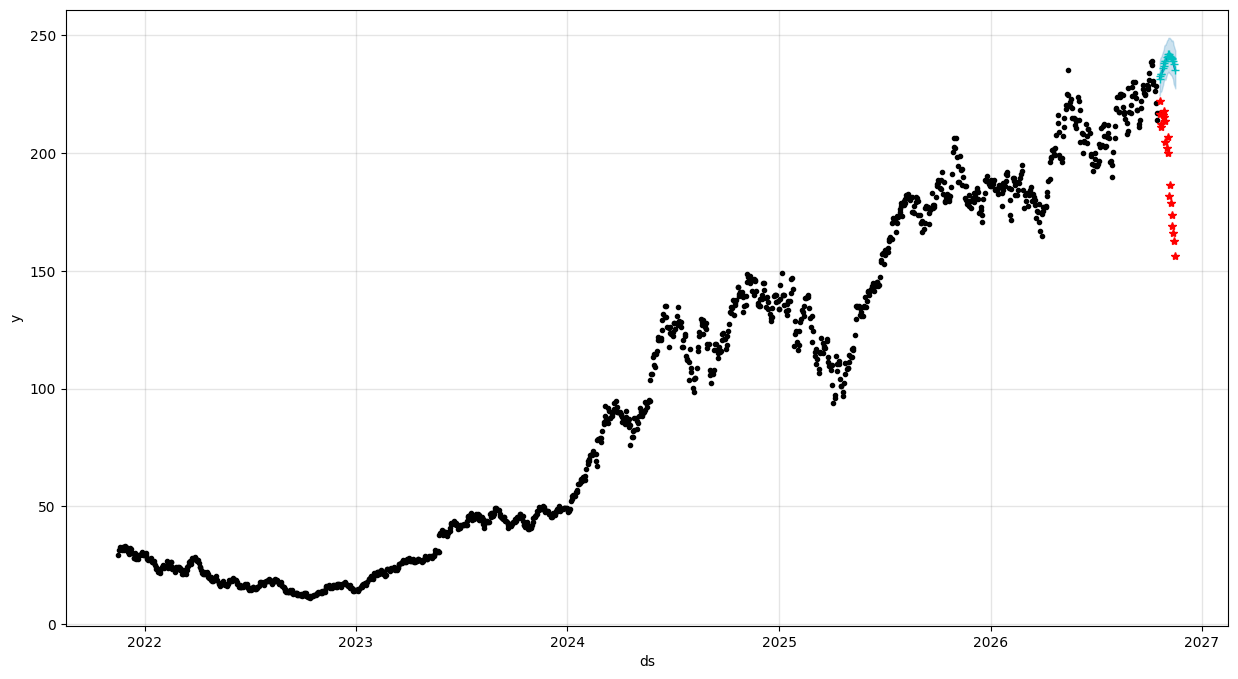

In [ ]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast = model.predict(test)

fig, ax = plt.subplots(figsize=(15, 8))
model.plot(forecast, ax=ax)               # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test['ds'], test['y'], '*r')   # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test['ds'], forecast['yhat'], '+c')    # Valores reales.

#color rojo representan las predicciones
#color azul datos reales


# <font color=orange>**Interpretación Gráfica Facebook-Meta-Prophet**

-----------------------------------------------------------------------------

Puntos Rojos -> predicciones
Puntos azules -> Datos reales
parte sombreada -> intervalo de confianza de los datos

Los puntos negros representan los datos de entrenamiento, las estrellas rojas son los precios reales de prueba y las marcas celestes corresponden al pronóstico. La zona sombreada muestra el intervalo de incertidumbre del modelo. Prophet mantuvo su pronóstico cerca del nivel previo, mientras que el precio real cayó y se alejó de esa zona. El RMSE de 47.977 dólares refleja esa separación.


-----------------------------------------------------------------------------


# **4 - Long Short Term Memory (LSTM)**

# **DATOS ORIGINALES**

In [ ]:
import tensorflow as tf

In [ ]:
test.head()

,ds,y
1284,2026-10-20,216.470001
1285,2026-10-21,221.970001
1286,2026-10-22,212.210007
1287,2026-10-23,210.960007
1288,2026-10-26,216.000000


In [ ]:
def preparando_datos(myData, myDate):

  # ++++++++ TRAIN +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de entrenamiento son previos a la fecha "Date" que indiques y
  # tomarán hisotriales en este caso de 12 períodos previos.
  Train_Data = myData['y'][myData['ds'] < myDate].to_numpy()

  periodo = 12   # 12 meses al año

  Data_Train = []
  Data_Train_X = []
  Data_Train_Y = []

  for i in range(0, len(Train_Data), periodo):    # observa que va formando el Train set con historiales de 12 períodos consecutivos.
    try:
      Data_Train.append(Train_Data[i : i + periodo])
    except:
      pass


  # En ocasiones hay datos perdidos, en cuyo caso la última serie
  # de datos la eliminamos:
  if len(Data_Train[-1]) < periodo:
    Data_Train.pop(-1)


  # Hay que darle la forma (dimensionalidad) que requieren los modelos
  # de aprendizaje profundo, en particular la librería de TensorFlow:
  #     (batch_size, sequence_length, input_dimension).

  Data_Train_X = Data_Train[0 : -1]
  Data_Train_X = np.array(Data_Train_X)
  Data_Train_X = Data_Train_X.reshape((-1, periodo, 1))

  Data_Train_Y = Data_Train[1 : len(Data_Train)]
  Data_Train_Y = np.array(Data_Train_Y)
  Data_Train_Y = Data_Train_Y.reshape((-1, periodo, 1))


  # +++++++++++ TEST +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de prueba (Test) son posteriores a la fecha "Date" y que es el
  # último ciclo que deseas predecir:
  Test_Data = myData['y'][myData['ds'] >= myDate].to_numpy()

  # inicialización de listas:
  Data_Test = []
  Data_Test_X = []
  Data_Test_Y = []

  for i in range(0, len(Test_Data), periodo):
    try:
      Data_Test.append(Test_Data[i : i + periodo])
    except:
      pass


  if len(Data_Test[-1]) < periodo:
    Data_Test.pop(-1)

  Data_Test_X = Data_Test[0 : -1]
  Data_Test_X = np.array(Data_Test_X)
  Data_Test_X = Data_Test_X.reshape((-1, periodo, 1))

  Data_Test_Y = Data_Test[1 : len(Data_Test)]
  Data_Test_Y = np.array(Data_Test_Y)
  Data_Test_Y = Data_Test_Y.reshape((-1, periodo, 1))


  return Data_Train_X, Data_Train_Y, Data_Test_X, Data_Test_Y


In [ ]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date = '2024-09-11'   # A partir de esta fecha se empieza a generar el Test.

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp, threshold_Date)#aplica df temporal

In [ ]:
# Podemos definir la manera en que el tamaño de paso (learning-rate) varíe
# en cada época. Es usual definir también algunas funciones, exponenciales,
# por ejemplo. Por el momento definamos valores constantes por intervalos:

def scheduler(epoch):

  if epoch <= 100:
    lrate = 0.05
  elif epoch <= 180:
    lrate = 0.0005
  elif epoch <=190:
    lrate = 0.00005
  else:
    lrate = (10 ** -5)

  return lrate


callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - loss: 3003.3792 - root_mean_squared_error: 54.8031 - val_loss: 6879.8105 - val_root_mean_squared_error: 82.9446 - learning_rate: 0.0500
Epoch 2/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - loss: 2021.2091 - root_mean_squared_error: 44.9579 - val_loss: 281.0938 - val_root_mean_squared_error: 16.7659 - learning_rate: 0.0500
Epoch 3/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - loss: 405.8349 - root_mean_squared_error: 20.1453 - val_loss: 1054.8647 - val_root_mean_squared_error: 32.4787 - learning_rate: 0.0500
Epoch 4/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - loss: 699.8490 - root_mean_squared_error: 26.4547 - val_loss: 2903.8499 - val_root_mean_squared_error: 53.8874 - learning_rate: 0.0500
Epoch 5/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - loss: 981.3477 - root_mean_squared_error: 31.3265 - val_loss: 10422.3096 - val_root_mean_squared_error: 102.0897 - learning_rate: 0.0500
Epoch 6/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - loss: 2

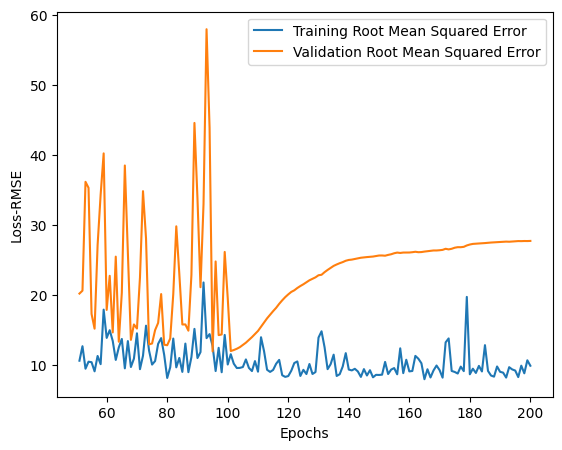

In [ ]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(20, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(12, activation='linear')
                                      ])
  return model


# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback],

                       )



N = 50  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

In [ ]:
pred_LSTM=my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM.shape

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step


(6624,)

In [ ]:
# Calculamos el error RMSE:

pred_LSTM = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM = pred_LSTM.reshape(-1)[-20:]  # Elegir los últimos 20 valores
rmse = np.sqrt(mean_squared_error(test['y'].values, pred_LSTM))

print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step

Error-Modelo-FacebookProphet: RMSE: 23.180


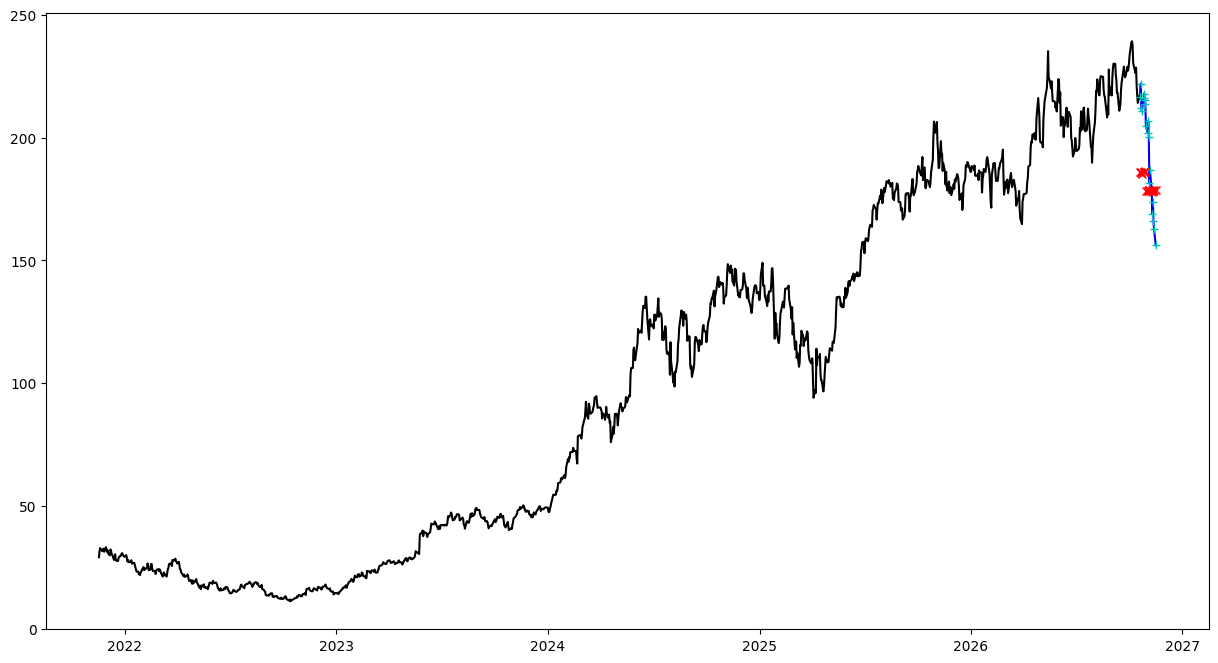

In [ ]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(15, 8))
ax = plt.plot(train['ds'], train['y'], '-k')  # Datos de entrenamiento de 1949 a 1959.
ax = plt.plot(test['ds'], test['y'], '-b')    # Datos de prueba del año 1960.
ax = plt.plot(test['ds'], test['y'], '+c')    # Datos de prueba del año 1960.
ax = plt.plot(test['ds'], pred_LSTM, 'xr')  # Predicciones del modelo del año 1960.

**Habría que buscar la mejor arquitectura y ejecutarlo varias veces para obtener un mejor resultado.**

# <font color=orange>**Interpretación Gráfica Long Short Term Memory (LSTM)**

----------------------------------------------------------------------------
Las predicciones de LSTM se agruparon cerca de los 180 dólares, mientras que los valores reales recorrieron un rango mucho más amplio. Al inicio de la prueba, el modelo estimó precios menores que los observados y, cerca del final, quedó por encima de varios valores reales. La red se acercó a un nivel intermedio, pero representó poco de la caída. El RMSE reportado fue de 23.180 dólares.

----------------------------------------------------------------------------

# <font color=orange>**Interpretación Valores RMSE Obtenidos de los modelos Ingenuo, ARIMA, Prophet y LSTM aplicado con Datos Orginales**</font>

-----------------------------------------------------------------------------

Los resultados obtenidos de RMSE, fueron los siguientes:

| # | Modelo  | Datos Originales RMSE |
|---|---------|-----------------------|
| 1 | Modelo Ingenuo (Baseline / Persistance / Naive model) |7.011 |
| 2 | Modelo ARIMA |7.476  |
| 3 | Modelo Facebook-Meta-Prophet |47.977 |
| 4 | Long Short Term Memory (LSTM) |23.180 |

**<font color=orange>INTERPRETACIÓN Y CONCLUSIÓN DE LA PRÁCTICA: </FONT>**
En el tramo evaluado, el modelo ingenuo obtuvo el menor error y ARIMA quedó cerca. LSTM capturó poco de la caída, mientras que Prophet mantuvo sus estimaciones por encima del precio real y registró el error más alto. Estos resultados corresponden a las condiciones de la práctica. El ingenuo y ARIMA incorporaron cada observación nueva para pronosticar el siguiente paso, mientras que Prophet generó el pronóstico del tramo completo con el modelo ya ajustado.
---------------------------------------------------------------------------

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **A continuación, se aplicaran los mismos modelos planteados anteriormente (Ingenuo, ARIMA, Prophet y LSTM), pero aplicando escalamiento MinMaxScaler al conjunto de datos que estamos trabajando (ADJ-CLOSE).**

# **0 -PREPARACIÓN DATOS PARA ESCALAMIENTO**

# **DATOS ESCALADOS**

In [ ]:
scaler = MinMaxScaler(feature_range=(0, 1))#aplica escalamiento rango 0,1

#Aplica Escalamiento a Entrenamiento y Prueba
train.loc[:, 'y_escalado'] = scaler.fit_transform(train[['y']])
test.loc[:, 'y_escalado']=scaler.transform(test[['y']])

In [ ]:
train.head() #para visualizar nueva columna con los valores 'y' escalados

,ds,y,y_escalado
0,2021-11-17,29.132683,0.078692
1,2021-11-18,31.536097,0.089231
2,2021-11-19,32.840351,0.094950
3,2021-11-22,31.815866,0.090458
4,2021-11-23,31.606783,0.089541


In [ ]:
#Elimina columna 'y' para quedarnos solo con las columnas: 'ds'  'y_escalado'
train_escalado=train.drop(columns=['y'])
test_escalado=test.drop(columns=['y'])

In [ ]:
train_escalado.head()#verifica eliminacion columna 'y'

,ds,y_escalado
0,2021-11-17,0.078692
1,2021-11-18,0.089231
2,2021-11-19,0.094950
3,2021-11-22,0.090458
4,2021-11-23,0.089541


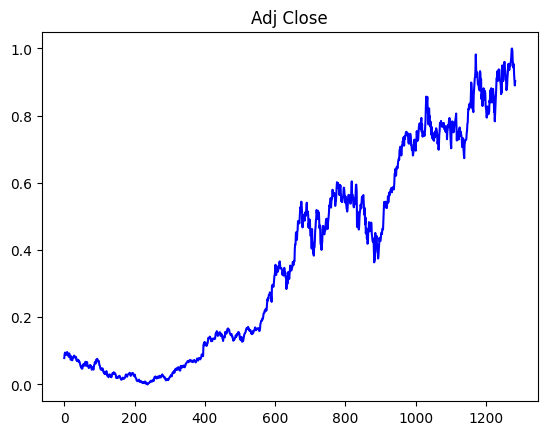

In [ ]:
train_escalado['y_escalado'].plot(title='Adj Close', style='-b')
plt.show()

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo Obtenido en Datos Originales**

-----------------------------------------------------------------------------
Al aplicar Min-Max, se conserva la forma de la serie. Se distinguen la caída inicial, la recuperación y el crecimiento de los últimos años. El eje vertical ahora muestra valores normalizados entre 0 y 1 para el conjunto de entrenamiento, y el eje horizontal indica la posición de cada registro.

-----------------------------------------------------------------------------

In [ ]:
test_escalado['y_escalado'].values   #muestra valores del test con los datos escalados

array([0.90015489, 0.92427206, 0.88147507, 0.87599389, 0.89809396,
       0.90660076, 0.89537532, 0.88783322, 0.84828104, 0.83696789,
       0.85727018, 0.82850498, 0.74725205, 0.76935212, 0.73440414,
       0.69151943, 0.71274252, 0.6796801 , 0.66503442, 0.66503442])

# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ESCALADOS**

In [ ]:
history = [x for x in train_escalado['y_escalado'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test_escalado['y_escalado'])):
  # Obtenemos las predicciones:
  yhat_scaled = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat_scaled)

  # Observaciones-registros reales:
  obs_scaled = test_escalado.iloc[i]['y_escalado']   # Ahora vamos tomando los datos de Test.
  history.append(obs_scaled)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_scaled, yhat_scaled))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test_escalado['y_escalado'].values, predictions))
print('\nError-Modelo-Naive con datos escalados: RMSE: %.3f' % rmse)

>Esperado-real = 0.900, Predicción = 0.903
>Esperado-real = 0.924, Predicción = 0.900
>Esperado-real = 0.881, Predicción = 0.924
>Esperado-real = 0.876, Predicción = 0.881
>Esperado-real = 0.898, Predicción = 0.876
>Esperado-real = 0.907, Predicción = 0.898
>Esperado-real = 0.895, Predicción = 0.907
>Esperado-real = 0.888, Predicción = 0.895
>Esperado-real = 0.848, Predicción = 0.888
>Esperado-real = 0.837, Predicción = 0.848
>Esperado-real = 0.857, Predicción = 0.837
>Esperado-real = 0.829, Predicción = 0.857
>Esperado-real = 0.747, Predicción = 0.829
>Esperado-real = 0.769, Predicción = 0.747
>Esperado-real = 0.734, Predicción = 0.769
>Esperado-real = 0.692, Predicción = 0.734
>Esperado-real = 0.713, Predicción = 0.692
>Esperado-real = 0.680, Predicción = 0.713
>Esperado-real = 0.665, Predicción = 0.680
>Esperado-real = 0.636, Predicción = 0.665

Error-Modelo-Naive con datos escalados: RMSE: 0.031


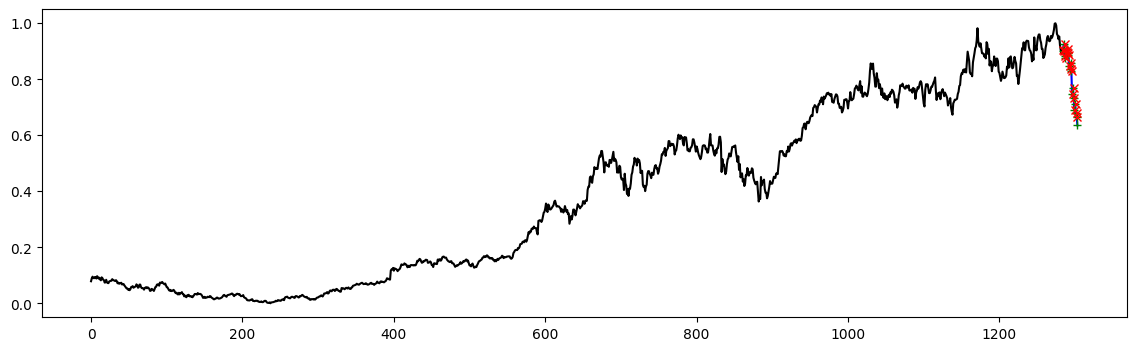

In [ ]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(14, 4))
ax = plt.plot(train_escalado['y_escalado'], '-k')  # Datos de entrenamiento (los históricos).
ax = plt.plot(test_escalado['y_escalado'], '-b')    # Datos de prueba reales (los del útimo año a predecir).
ax = plt.plot(test_escalado['y_escalado'],'+g')
ax = plt.plot(test_escalado.index, predictions, 'xr')

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo obtenido en el modelo ingenuo con los datos originales**

----------------------------------------------------------------------------
El modelo ingenuo escalado sigue la caída con el mismo retraso de un registro que en la versión original. Su RMSE fue de 0.031 en la escala normalizada. Como el modelo toma el último precio observado en ambas versiones, al convertir las predicciones de vuelta a dólares se obtiene el mismo pronóstico.

----------------------------------------------------------------------------

# **2 - Modelo ARIMA**
# **DATOS ESCALADOS**

In [ ]:
#copia df con Conjunto Entrenamiento
train_escalado2=train_escalado.copy()
train_escalado2.head()

,ds,y_escalado
0,2021-11-17,0.078692
1,2021-11-18,0.089231
2,2021-11-19,0.094950
3,2021-11-22,0.090458
4,2021-11-23,0.089541


In [ ]:
#copia df Conjunto de Prueba
test_escalado2=test_escalado.copy()
test_escalado2.head()

,ds,y_escalado
1284,2026-10-20,0.900155
1285,2026-10-21,0.924272
1286,2026-10-22,0.881475
1287,2026-10-23,0.875994
1288,2026-10-26,0.898094


In [ ]:
train_escalado2 = train_escalado2.set_index('ds') #Aplica ds como índice en conjunto entrenamiento

In [ ]:
test_escalado2 =test_escalado2.set_index('ds')   #Aplica ds como índice en conjunto de Prueba

In [ ]:
train_escalado2.head()  #Verifica datos escalados Entrenamiento

,y_escalado
ds,
2021-11-17,0.078692
2021-11-18,0.089231
2021-11-19,0.094950
2021-11-22,0.090458
2021-11-23,0.089541


In [ ]:
test_escalado2.head() #Verificar datos Escalados Prueba

,y_escalado
ds,
2026-10-20,0.900155
2026-10-21,0.924272
2026-10-22,0.881475
2026-10-23,0.875994
2026-10-26,0.898094


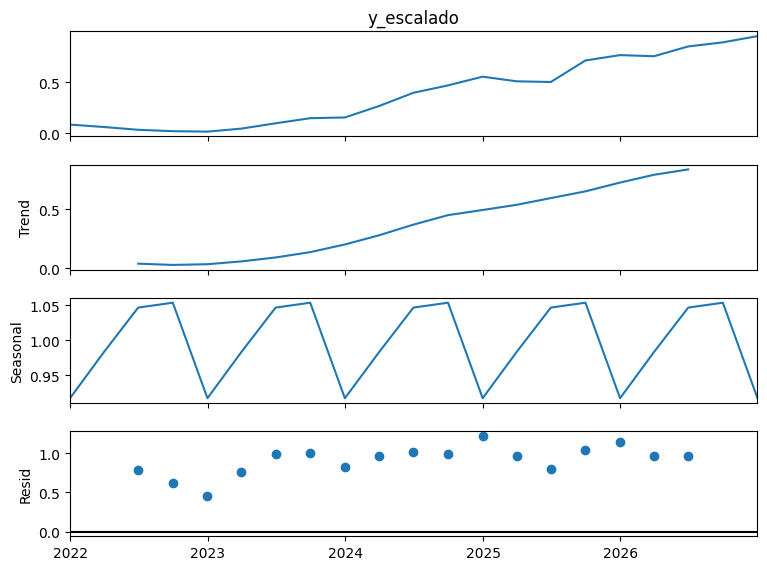

In [ ]:
# Gráficos de descomposición estacional con datos escalados:
decomposition = seasonal_decompose(train_escalado2['y_escalado'].resample('QE').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

# <FONT COLOR=ORANGE>**Interpretación Gráfica. Compartiva con Datos Originales**

------------------------------------------------------------------------
La serie escalada y su tendencia conservan el crecimiento que se observó en los datos originales. El componente estacional sigue mostrando un ciclo que se repite cada año, pero cambia la forma de los factores. Esto se debe a que la descomposición es multiplicativa y el escalamiento modifica las proporciones con respecto a la tendencia. En los residuos, varios de los primeros trimestres se alejan más de 1.

--------------------------------------------------------------------------

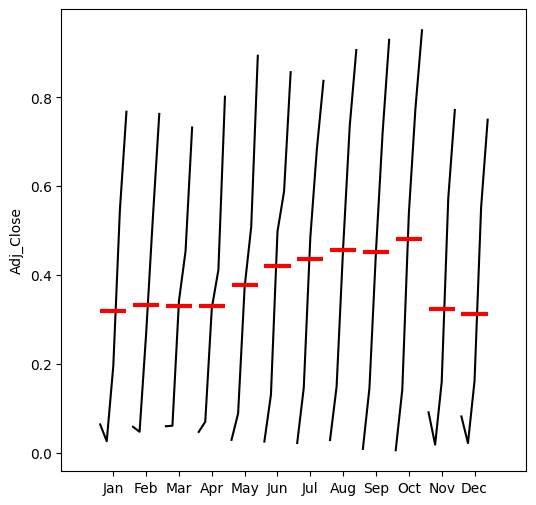

In [ ]:
# Gráfica para detección de estacionalidad mensual con datos escalados:
fig = month_plot(train_escalado2['y_escalado'].resample('M').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

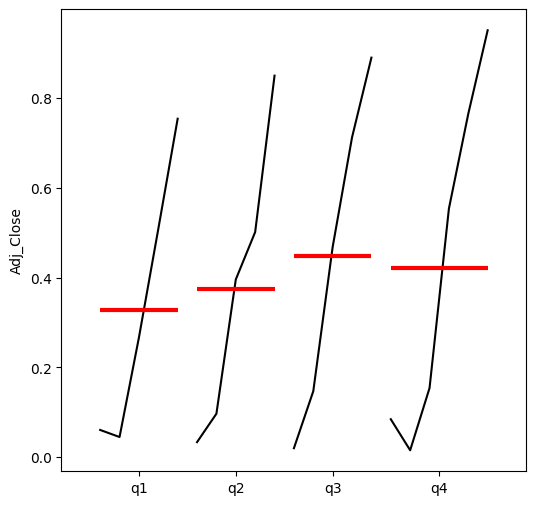

In [ ]:
# Si queremos graficar y detectar estacionalidad trimestral con datos escalados:
fig = quarter_plot(train_escalado2['y_escalado'].resample('Q').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

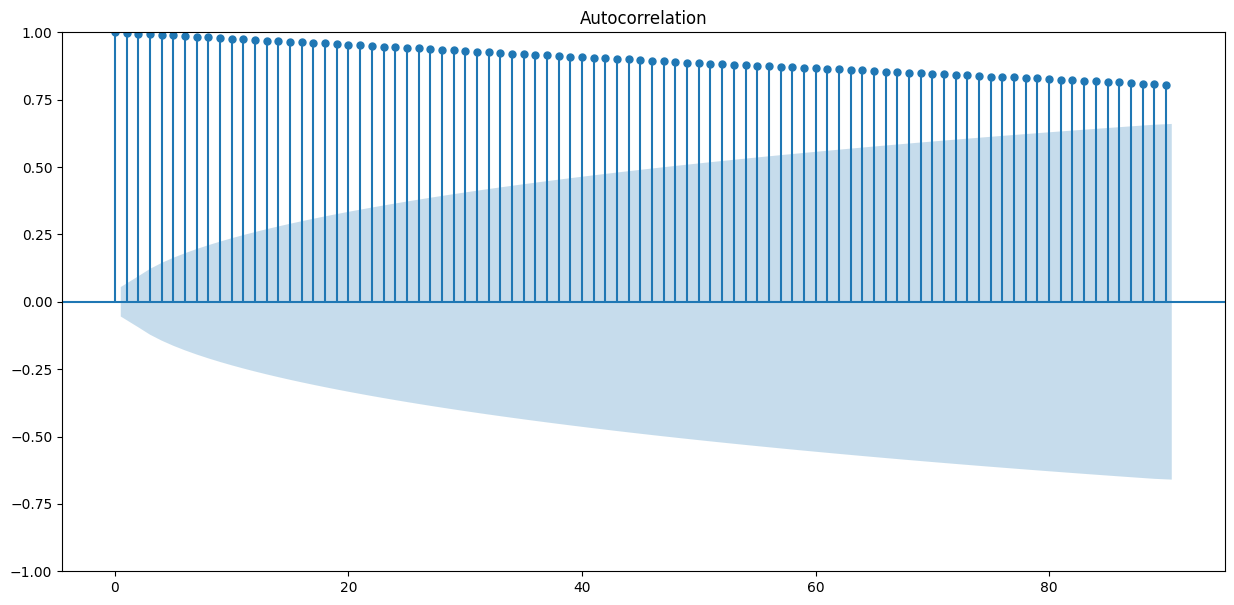

In [ ]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function) con datos escalados
fig,ax = plt.subplots(figsize = (15,7))
plot_acf(train_escalado2['y_escalado'], lags = 90,ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
plt.show()                          # que define la partición en el eje horizontal. El área no sombreada nos habla de
                                    # la cantidad de períodos de tiempo hacia atrás cuya información proporcionada es
                                    # significativa para la predicción futura.


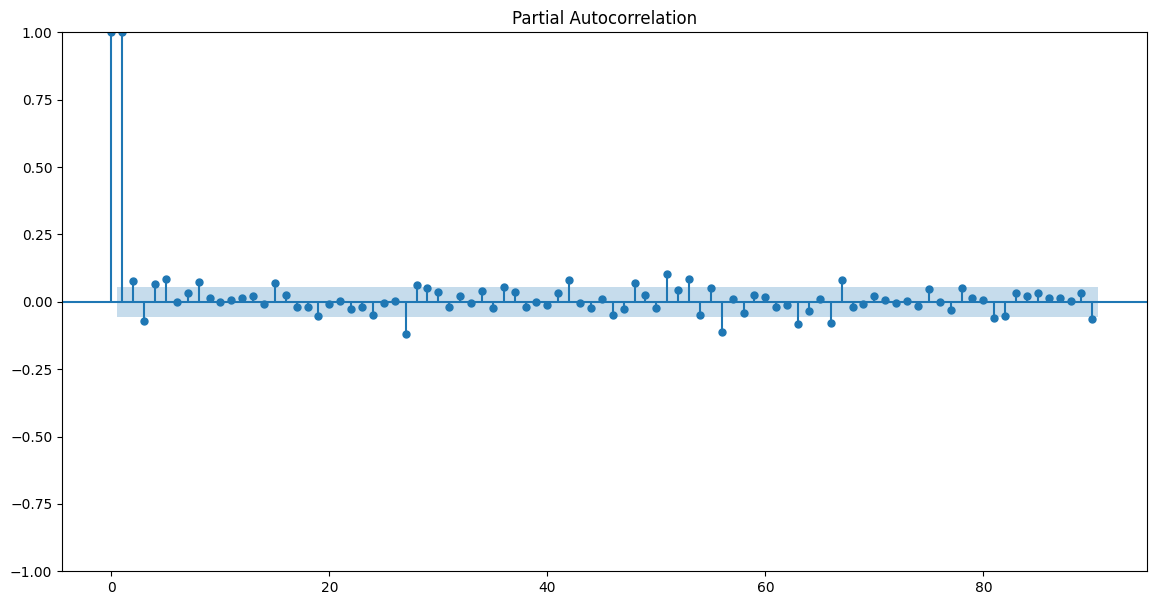

In [ ]:
# Gráfico de Autocorrelación Parcial (PACF) con datos escalados:
fig, ax = plt.subplots(figsize = (14,7))
plot_pacf(train_escalado2['y_escalado'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

In [ ]:
# Definamos la siguiente lista de registros de Adj Close en el tiempo con datos escalados:
history_escalado = [x for x in train_escalado2.loc[:,'y_escalado'].values]   # train-ndarray : columna solo con los registros de Adj Close "y".
                               # history-list : lista con los datos del train.

predictions_escalado = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test_escalado2['y_escalado'])):
  #
  months_in_year = 12
  diff = difference(history_escalado, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.
  model_escalado = ARIMA(diff, order=(1,0,5),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit_escalado = model_escalado.fit(method_kwargs={'maxiter':500})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat_escalado = model_fit_escalado.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat_escalado = inverse_difference(history_escalado, yhat_escalado, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions_escalado.append(yhat_escalado)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs_escalado = test_escalado2.iloc[i]['y_escalado']   #  cada dato es un flotante.
  history_escalado.append(obs_escalado)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_escalado, yhat_escalado))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test_escalado2['y_escalado'].values, predictions_escalado))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 0.900, Predicción = 0.925
>Esperado-real = 0.924, Predicción = 0.932
>Esperado-real = 0.881, Predicción = 0.935
>Esperado-real = 0.876, Predicción = 0.892
>Esperado-real = 0.898, Predicción = 0.855
>Esperado-real = 0.907, Predicción = 0.903
>Esperado-real = 0.895, Predicción = 0.912
>Esperado-real = 0.888, Predicción = 0.912
>Esperado-real = 0.848, Predicción = 0.864
>Esperado-real = 0.837, Predicción = 0.842
>Esperado-real = 0.857, Predicción = 0.833
>Esperado-real = 0.829, Predicción = 0.876
>Esperado-real = 0.747, Predicción = 0.841
>Esperado-real = 0.769, Predicción = 0.786


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


>Esperado-real = 0.734, Predicción = 0.735
>Esperado-real = 0.692, Predicción = 0.753
>Esperado-real = 0.713, Predicción = 0.739
>Esperado-real = 0.680, Predicción = 0.734
>Esperado-real = 0.665, Predicción = 0.699
>Esperado-real = 0.636, Predicción = 0.682

Error-Modelo-ARIMA: RMSE: 0.038


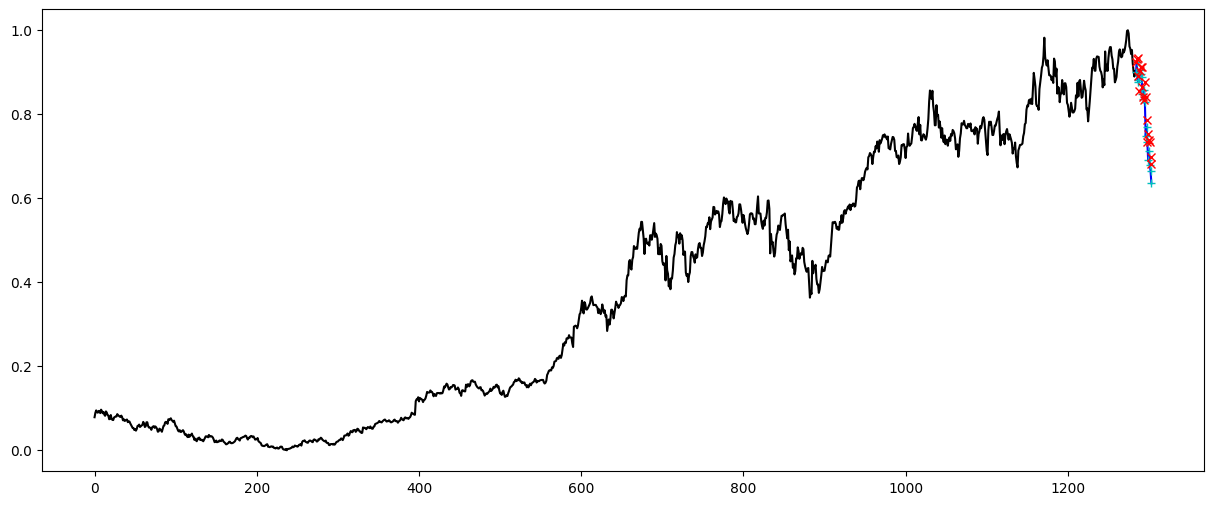

In [ ]:
# Veamos su gráfico:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train_escalado['y_escalado'], '-k')
ax = plt.plot(test_escalado['y_escalado'], '-b')
ax = plt.plot(test_escalado['y_escalado'], '+c')
ax = plt.plot(test_escalado.index, predictions_escalado, 'xr')

# <FONT COLOR=ORANGE>**Interpretación Gráfica Modelo ARIMA, Comparativa con datos originales**

------------------------------------------------------------------------
ARIMA siguió la dirección general de la caída, igual que con los datos originales. En varios puntos del tramo final, las cruces rojas quedan por encima de los valores reales. El RMSE fue de 0.038 en la escala normalizada y quedó por encima del 0.031 del modelo ingenuo evaluado en esa misma escala.


-------------------------------------------------------------------------

# **3 - Modelo Facebook-Meta-Prophet**
# **DATOS ESCALADOS**

In [ ]:
df_temp_escalado=df_temp.copy() #copia en nuevo df
df_temp_escalado.head()

,ds,y
0,2021-11-17,29.132683
1,2021-11-18,31.536097
2,2021-11-19,32.840351
3,2021-11-22,31.815866
4,2021-11-23,31.606783


In [ ]:
df_temp_escalado= df_temp_escalado.rename(columns={'Date':'ds','y_escalado':'y'})
df_temp_escalado.head()

,ds,y
0,2021-11-17,29.132683
1,2021-11-18,31.536097
2,2021-11-19,32.840351
3,2021-11-22,31.815866
4,2021-11-23,31.606783


In [ ]:
train_escalado = df_temp_escalado.iloc[0:-20,:] #partición Entrenamiento. Todos menos los últimos 20 registros
test_escalado = df_temp_escalado.iloc[-20:,:] #partición Prueba. Solo los últimos 20 registros

In [ ]:
#Aplica Escalamiento MinMaxScaler a entrenamiento y prueba
scaler = MinMaxScaler(feature_range=(0, 1))
train_escalado.loc[:, 'y']=scaler.fit_transform(train_escalado[['y']])
test_escalado.loc[:, 'y']=scaler.transform(test_escalado[['y']])

In [ ]:
train_escalado.head()

,ds,y
0,2021-11-17,0.078692
1,2021-11-18,0.089231
2,2021-11-19,0.094950
3,2021-11-22,0.090458
4,2021-11-23,0.089541


In [ ]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model_escalado = Prophet(seasonality_mode='multiplicative',
                yearly_seasonality=True,
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30,)   # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model_escalado.fit(train_escalado)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [ ]:
# Calculamos el error RMSE con datos escalados:
pred_FP_escalado = model_escalado.predict(test_escalado)['yhat']
rmse = np.sqrt(mean_squared_error(test_escalado['y'], pred_FP_escalado))
print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet con datos escalados: RMSE: 0.208


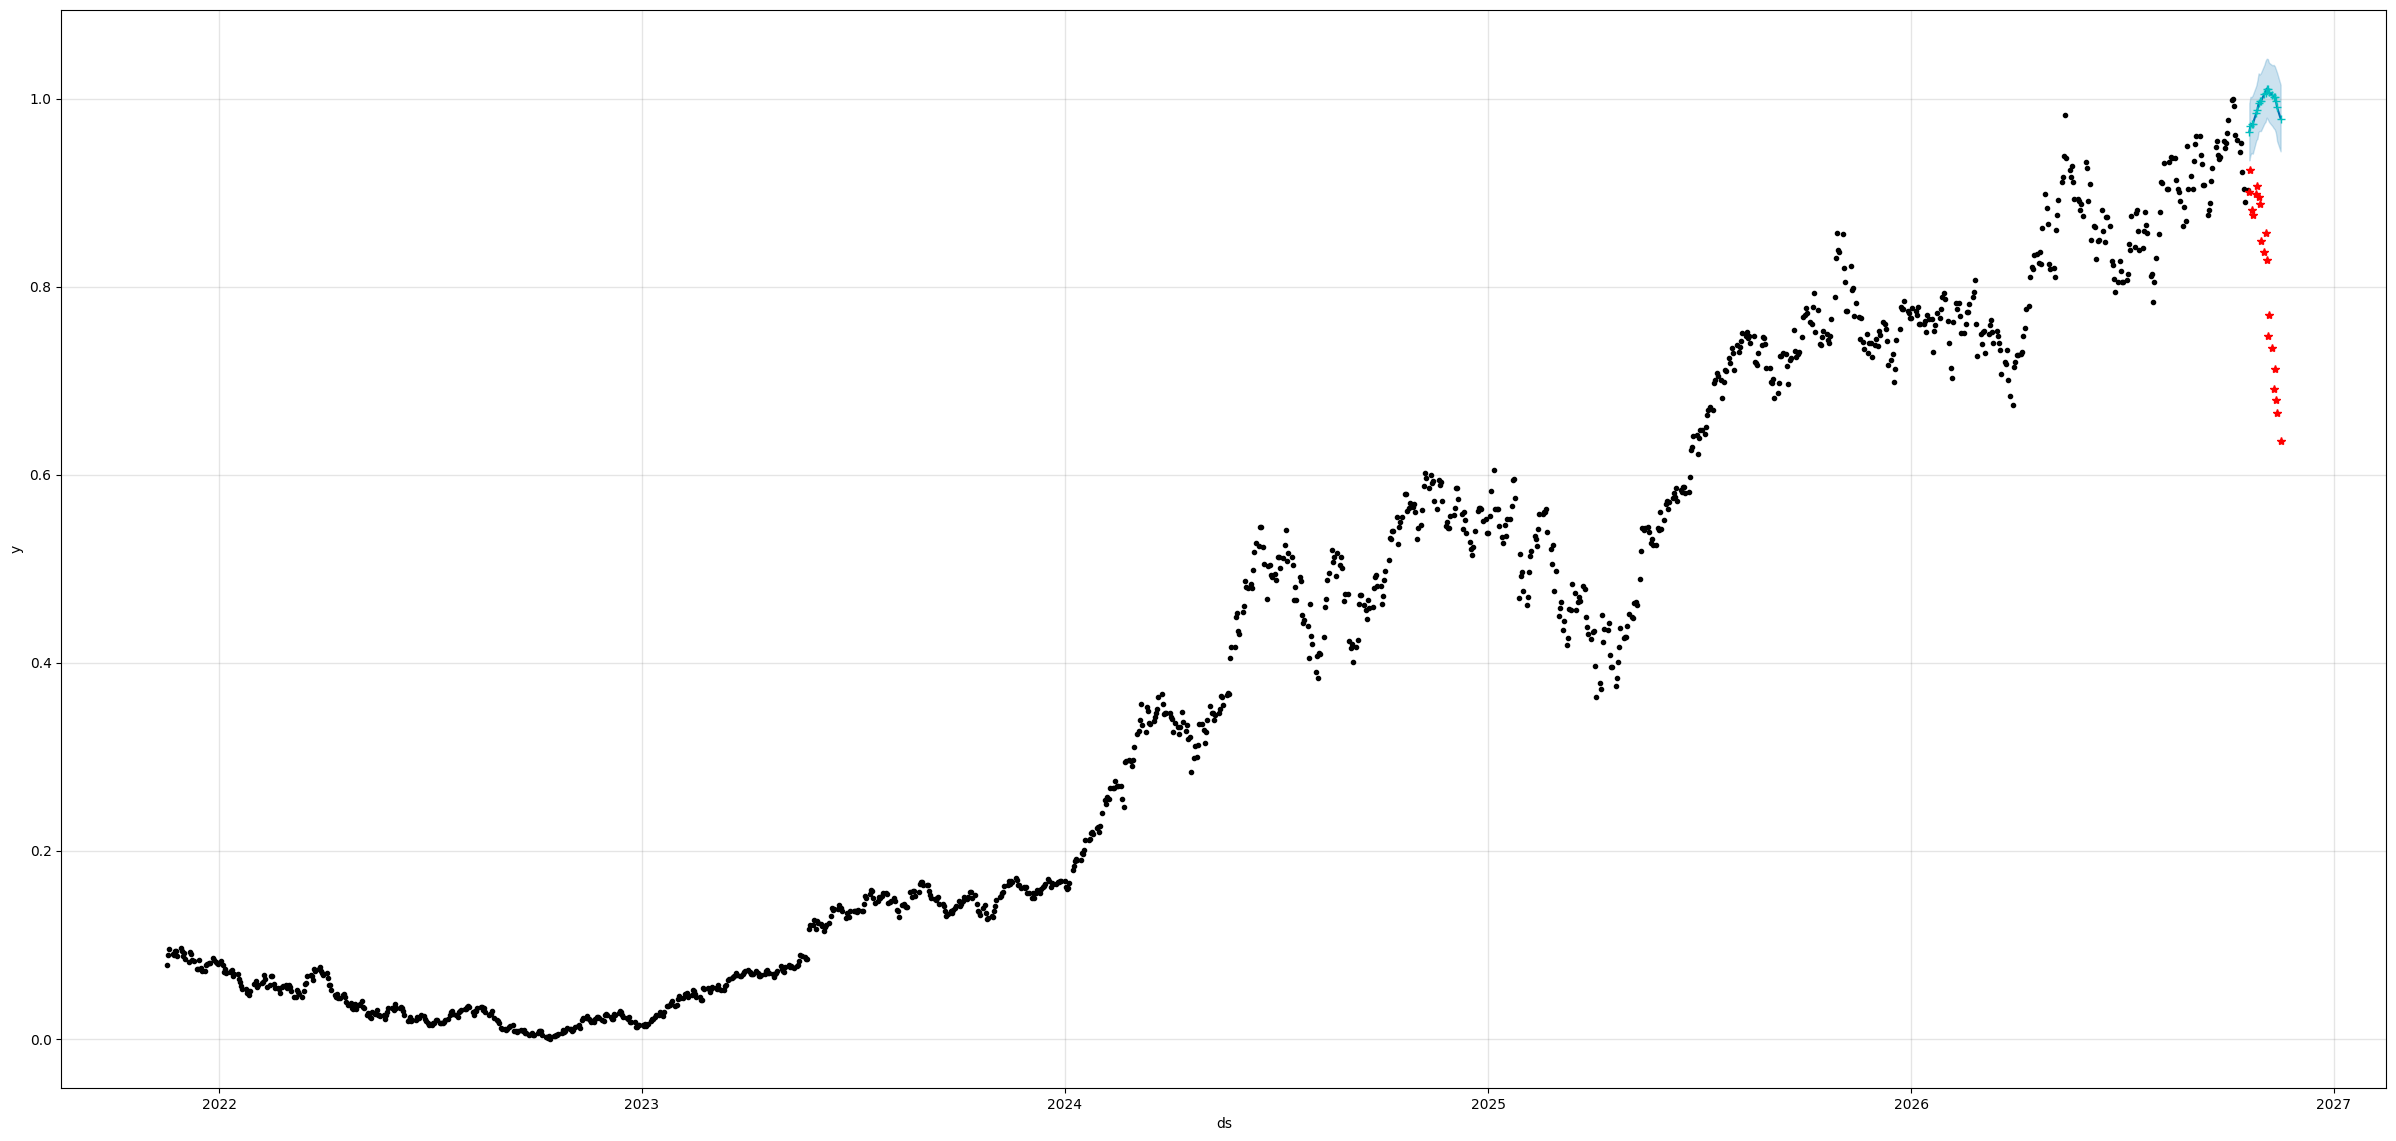

In [ ]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast_escalado = model_escalado.predict(test_escalado)

fig, ax = plt.subplots(figsize=(30, 14))
model_escalado.plot(forecast_escalado, ax=ax)       # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '*r') # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test_escalado['ds'], forecast_escalado['yhat'], '+c')  # Valores reales.

##<FONT COLOR=ORANGE>**Interpretación Gráfica. Compartiva con lo obtenido en datos originales**

------------------------------------------------------------------------
Después de escalar los datos, Prophet mantuvo un comportamiento parecido al de la versión original. El pronóstico se quedó cerca del nivel previo a la caída, mientras que las estrellas rojas, que representan los valores reales, siguieron bajando. El RMSE de 0.208 en la escala normalizada refleja la diferencia entre el pronóstico y lo observado.

-----------------------------------------------------------------------

# **4 - Long Short Term Memory (LSTM)**

# **DATOS ESCALADOS**

In [ ]:
test_escalado.head()

,ds,y
1284,2026-10-20,0.900155
1285,2026-10-21,0.924272
1286,2026-10-22,0.881475
1287,2026-10-23,0.875994
1288,2026-10-26,0.898094


In [ ]:
df_temp_escalado.head()

,ds,y
0,2021-11-17,0.078692
1,2021-11-18,0.089231
2,2021-11-19,0.094950
3,2021-11-22,0.090458
4,2021-11-23,0.089541


In [ ]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date_escalado = '2024-09-24'   # A partir de esta fecha se empieza a generar el Test.

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp_escalado, threshold_Date_escalado)

In [ ]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(200, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(12, activation='linear')
                                      ])
  return model

In [ ]:
def scheduler(epoch):
    if epoch <= 50:
        return 0.05
    elif epoch <= 100:
        return 0.01
    elif epoch <= 150:
        return 0.001
    else:
        return 0.0001

callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - loss: 2.2346 - root_mean_squared_error: 1.4949 - val_loss: 0.2206 - val_root_mean_squared_error: 0.4697 - learning_rate: 0.0500
Epoch 2/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 438ms/step - loss: 19.9717 - root_mean_squared_error: 4.4690 - val_loss: 0.8636 - val_root_mean_squared_error: 0.9293 - learning_rate: 0.0500
Epoch 3/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 655ms/step - loss: 0.8252 - root_mean_squared_error: 0.9084 - val_loss: 0.3415 - val_root_mean_squared_error: 0.5844 - learning_rate: 0.0500
Epoch 4/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 688ms/step - loss: 0.3161 - root_mean_squared_error: 0.5622 - val_loss: 0.3484 - val_root_mean_squared_error: 0.5903 - learning_rate: 0.0500
Epoch 5/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 461ms/step - loss: 0.4615 - root_mean_squared_error: 0.6793 - val_loss: 0.3285 - val_root_mean_squared_error: 0.5731 - learning_rate: 0.0500
Epoch 6/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 403ms/step - loss: 0.4368 - root_mean_squared_error: 0.66

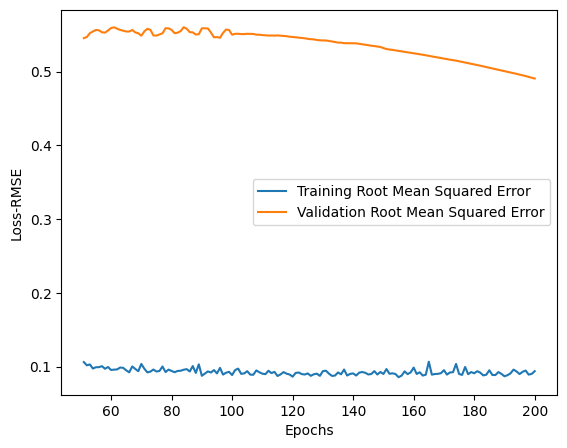

In [ ]:

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback],

                       )



N = 50  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

In [ ]:
#pred_LSTM = H.model.predict(Test_X) scaled
pred_LSTM_escalado = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM_escalado.shape

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step


(6480,)

In [ ]:
# Calculamos el error RMSE con datos escalados:

pred_LSTM_escalado = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)

pred_LSTM_escalado = pred_LSTM_escalado.reshape(-1)[-20:]  # Select the last 20 values
rmse = np.sqrt(mean_squared_error(test_escalado['y'].values, pred_LSTM_escalado))

print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step

Error-Modelo-FacebookProphet con datos escalados: RMSE: 0.529


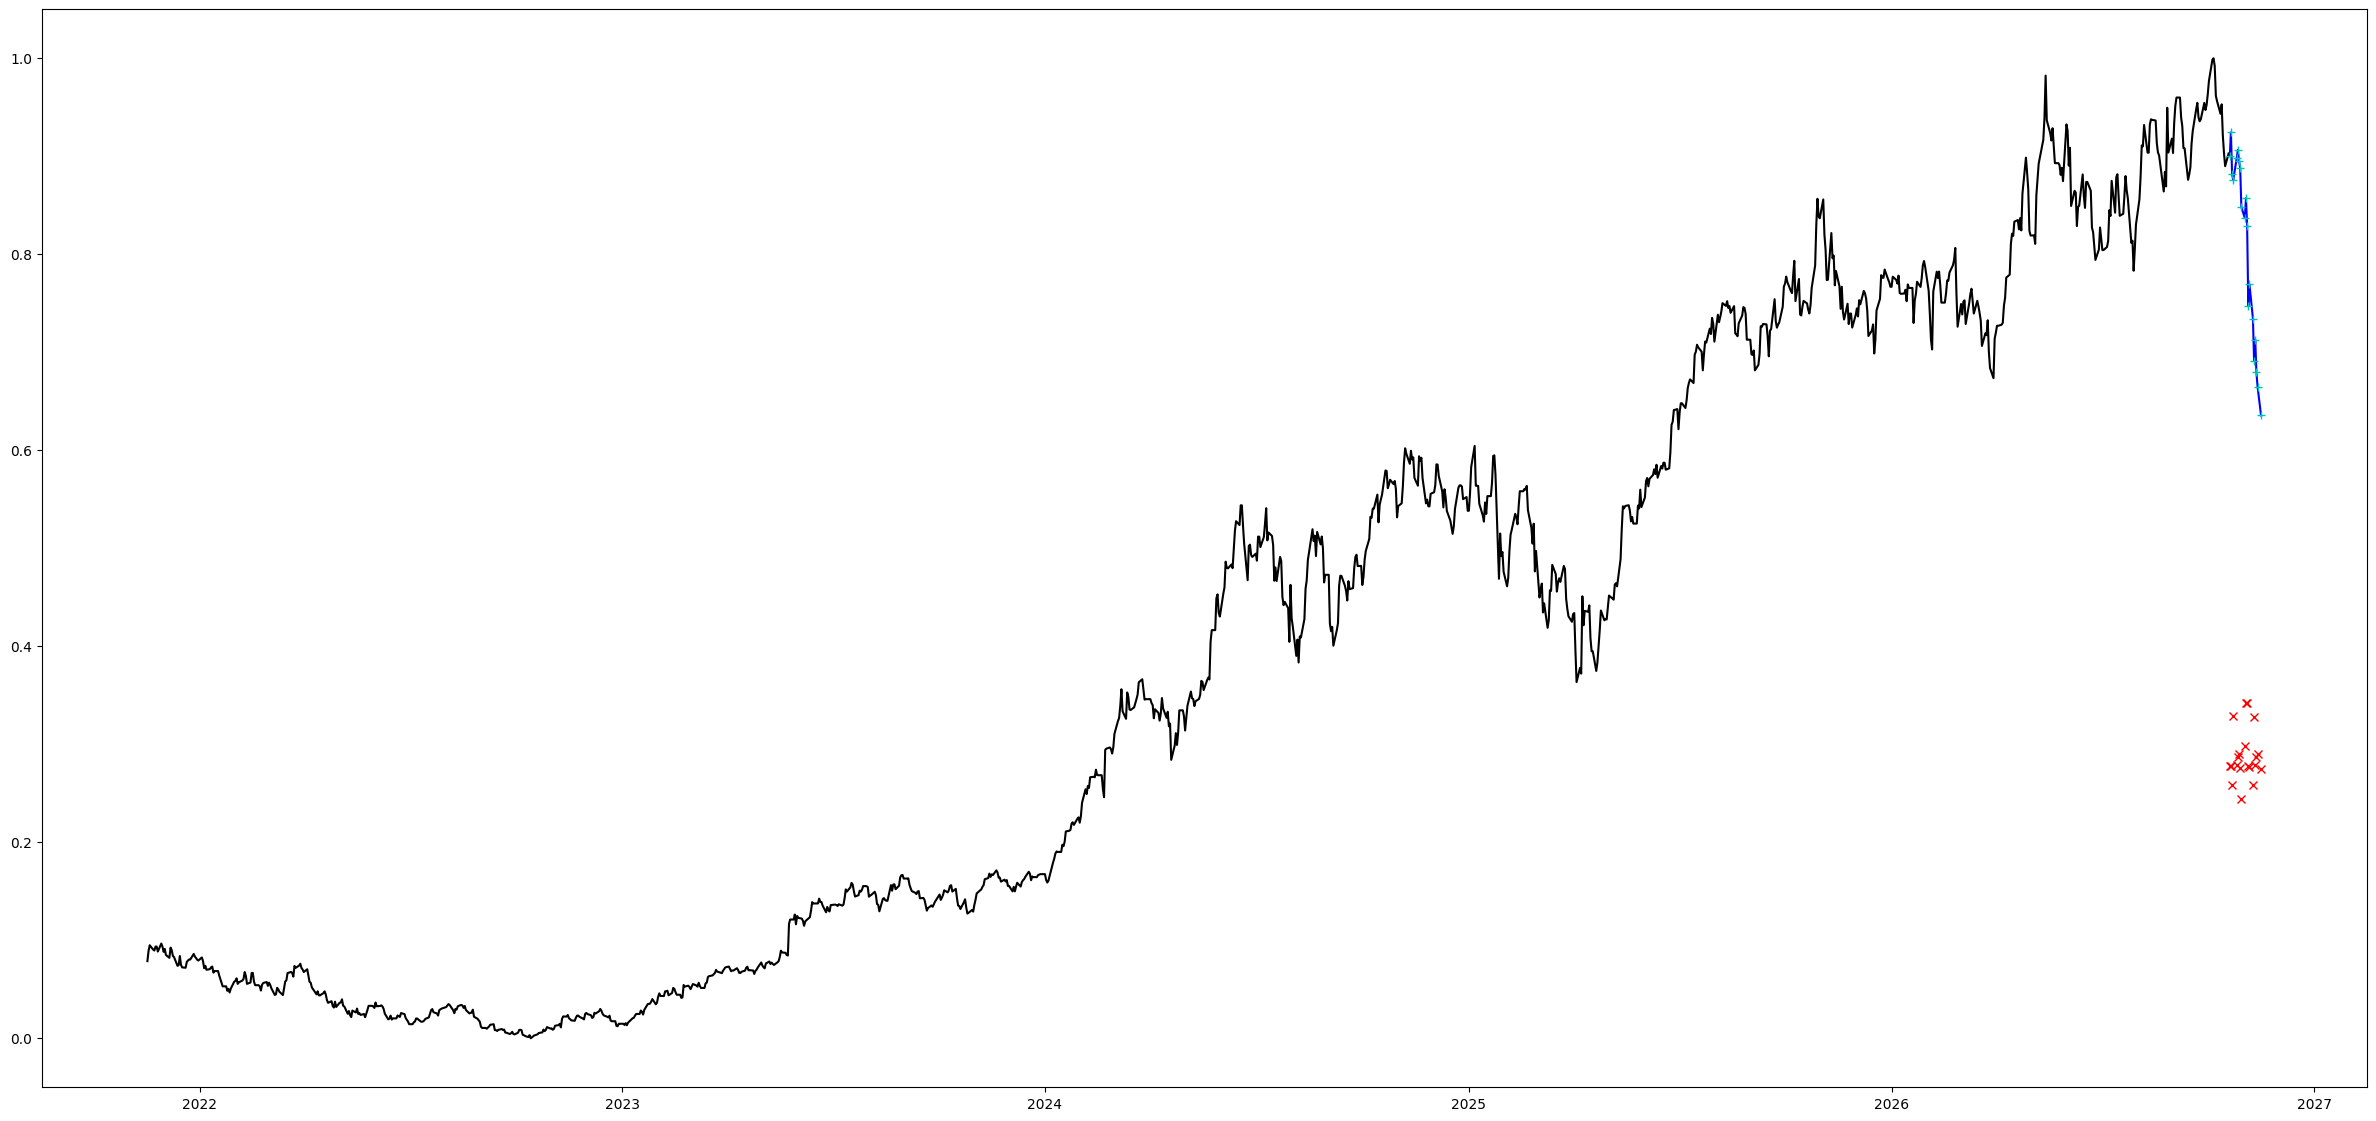

In [ ]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(30, 14))
ax = plt.plot(train_escalado['ds'], train_escalado['y'], '-k')  # Datos de entrenamiento de 1949 a 1959.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '-b')    # Datos de prueba del año 1960.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '+c')    # Datos de prueba del año 1960.
ax = plt.plot(test_escalado['ds'], pred_LSTM_escalado, 'xr')

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo obtenido en Datos Originales**

-----------------------------------------------------------------------------
En la gráfica completa, las predicciones de LSTM quedan muy por debajo de los precios reales y se agrupan en un rango estrecho. En la versión original se concentraban cerca de un nivel intermedio del tramo de prueba. La corrida de esta sección reportó un RMSE de 0.529, pero la red recibió la serie original y sus salidas se compararon con datos normalizados. Por ello, ese valor por sí solo no permite saber si el escalamiento mejoró o empeoró la predicción de LSTM.


-----------------------------------------------------------------------------

# **CONCLUSIÓN DE LA ACTIVIDAD**


----------------------------------------------------------------------------
# **¿Consideras que el escalamiento de los datos ayude a obtener mejores predicciones? Justifica tu respuesta.**
Considero que el escalamiento puede facilitar el entrenamiento de algunos modelos, pero por sí solo no garantiza mejores predicciones. En esta práctica, al aplicar Min-Max también cambiaron las unidades del RMSE. Para saber si el error realmente disminuyó, compararía las predicciones en dólares y para las mismas fechas.


### **Modelo Ingenuo**
El escalamiento no cambió el pronóstico. En ambas versiones, el modelo tomó el último precio observado para predecir el siguiente. El RMSE pasó de 7.011 dólares a 0.031 en la escala normalizada porque cambió la unidad en la que se expresa el error.

### **Modelo ARIMA**
Con datos originales y escalados, ARIMA siguió la caída general del precio, aunque en varios puntos pronosticó valores más altos que los reales. En ambas versiones obtuvo un error mayor que el modelo ingenuo. Al observar las gráficas, el escalamiento no mostró una mejora clara en la forma de seguir la caída.

### **Modelo Facebook-Meta-Prophet**
En las dos versiones, Prophet mantuvo sus estimaciones cerca del nivel anterior a la caída. A medida que bajó el precio real, aumentó la distancia entre lo pronosticado y lo observado. Por lo tanto, escalar los datos no resolvió la principal dificultad del modelo durante la prueba.
### **Modelo Long Short Term Memory (LSTM)**
En la gráfica original, las predicciones se concentraron cerca de los 180 dólares y reflejaron poco de la caída. En la corrida escalada, la red recibió la serie original y sus salidas se compararon con valores normalizados. Para saber si escalar los datos ayuda a LSTM, sería necesario repetir la evaluación con una escala consistente y verificar que cada predicción corresponda a la fecha que se está evaluando.


A continación se muestra una tabla comparativa con los valores RMSE de datos originales y datos escalados de cada uno de los modelos:


| Modelo | RMSE con datos originales (USD) | RMSE reportado en la sección escalada |
|---|---:|---:|
| Modelo Ingenuo | **7.011** | **0.031** |
| Modelo ARIMA | 7.476 | 0.038 |
| Modelo Facebook-Meta-Prophet | 47.977 | 0.208 |
| Modelo LSTM | 23.180 | 0.529 |

------------------------------------------------------------------------
# **INTERPRETACION de resultados RMSE**


### **RMSE DATOS ORIGINALES**
El modelo ingenuo obtuvo el menor RMSE, con 7.011 dólares, seguido de ARIMA con 7.476. La diferencia entre ambos fue de solo 0.465 dólares. LSTM y Prophet registraron errores mayores, de 23.180 y 47.977 dólares, respectivamente. En las gráficas se aprecia que ambos tuvieron más dificultades para seguir la caída del precio.

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

### **RMSE DATOS ESCALADOS**
El modelo ingenuo volvió a registrar el menor error, con 0.031, seguido de ARIMA con 0.038 y Prophet con 0.208. LSTM reportó 0.529, aunque ese resultado debe interpretarse con cautela por la diferencia de escalas en su evaluación. Los valores de esta columna se deben llevar a dólares antes de compararlos directamente con los RMSE originales.

+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **En conclusión:**
En el período analizado, usar el último precio observado fue suficiente para obtener el menor RMSE de los modelos probados. ARIMA quedó cerca, mientras que Prophet y LSTM tuvieron más dificultades para reflejar la caída. La práctica me permitió ver que un RMSE numéricamente menor después de escalar puede deberse al cambio de unidades. Para determinar si el escalamiento ayuda, compararía los errores en dólares, para las mismas fechas y con el mismo acceso a observaciones nuevas para todos los modelos.





------------------------------------------------------------------------

# **Referencias Bibliográficas**

Norton, V. (2011). Adjusted closing prices. arXiv preprint arXiv:1105.2956.

Luo, Y. X., & Ji, Y. (2022, September). Prediction of the Stock Adjusted Closing Price Based On Improved PSO-LSTM Neural Network. In 2022 International Conference on Machine Learning and Cybernetics (ICMLC) (pp. 43-48). IEEE.

Wijaya, A. C., Kusumaningrum, R., Sugiharto, A., & Aryotejo, G. (2024, July). Prophet Algorithm Optimization with Particle Swarm Optimization for Adjusted Closing Price Forecasting in Xiaomi Corporation. In 2024 7th International Conference on Informatics and Computational Sciences (ICICoS) (pp. 376-381). IEEE.


----------------------------------------------------------------------------

>> ## **Fin del Ejercicio de Series de Tiempo**